--- MEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN ---
          count        mean        std         min         25%         50%  \
Lenguaje                                                                     
Java      100.0   98.481313   8.847379   89.716025   94.052002   95.634376   
Python    100.0  367.161668  35.182278  345.439141  348.338187  352.236482   

                 75%         max  
Lenguaje                          
Java       99.470486  142.576551  
Python    359.326841  510.424935  


/tmp/ipykernel_3776/3879560371.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Lenguaje', y='Tiempo_ms', data=df, ax=axs[0], palette="Set2")


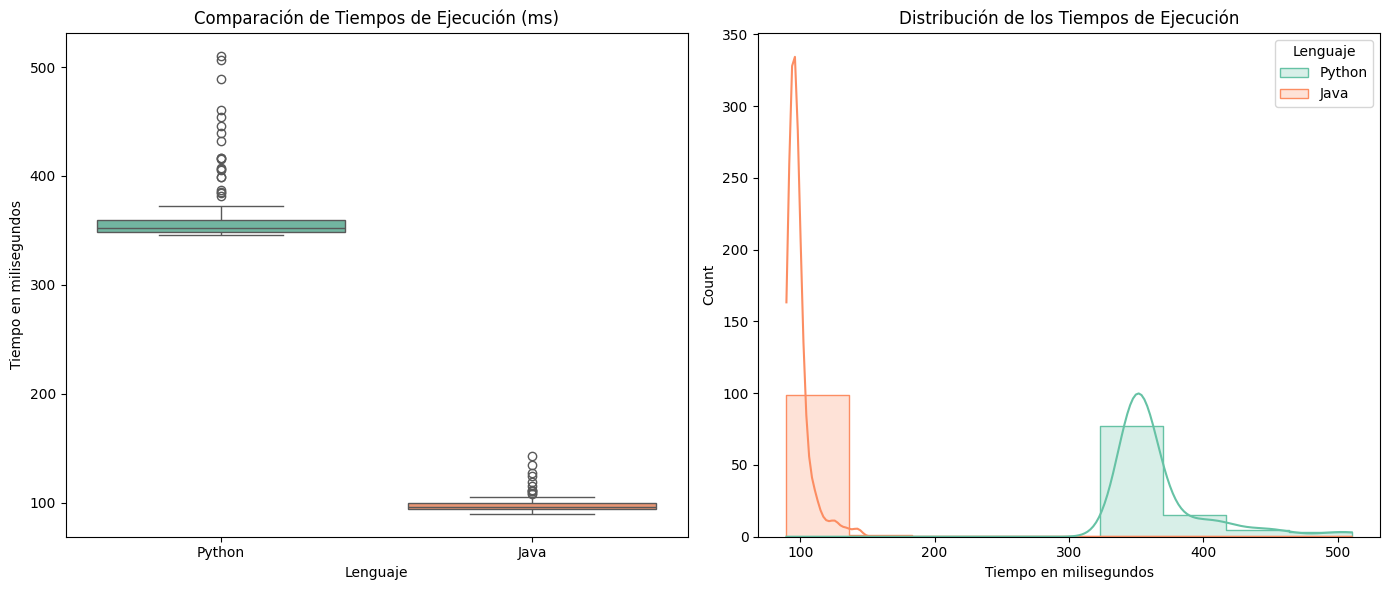


--- 1. PRUEBA DE NORMALIDAD (Shapiro-Wilk) ---
Python - p-value: 7.8817e-15
Java - p-value: 5.0085e-13

--- 2. PRUEBA DE COMPARACIÓN DE MEDIANAS/MEDIAS ---
Prueba Mann-Whitney (No paramétrica) - p-value: 2.5621e-34
Prueba T-Student Welch (Paramétrica) - p-value: 1.2254e-96


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 1. Cargar y consolidar los datos (Literal 3b)
try:
    df_py = pd.read_csv('tiempos_python.csv')
    df_java = pd.read_csv('tiempos_java.csv')
    df = pd.concat([df_py, df_java], ignore_index=True)
except FileNotFoundError:
    print("Por favor, asegúrate de haber subido tiempos_python.csv y tiempos_java.csv a Colab.")

# 2. Estadística Descriptiva (Literal 3c)
print("--- MEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN ---")
estadisticas = df.groupby('Lenguaje')['Tiempo_ms'].describe()
print(estadisticas)

# 3. Visualización de los datos (Literal 3c)
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot para ver medianas y valores atípicos (outliers)
sns.boxplot(x='Lenguaje', y='Tiempo_ms', data=df, ax=axs[0], palette="Set2")
axs[0].set_title('Comparación de Tiempos de Ejecución (ms)')
axs[0].set_ylabel('Tiempo en milisegundos')

# Histograma para ver la distribución de los datos
sns.histplot(data=df, x='Tiempo_ms', hue='Lenguaje', kde=True, element="step", ax=axs[1], palette="Set2")
axs[1].set_title('Distribución de los Tiempos de Ejecución')
axs[1].set_xlabel('Tiempo en milisegundos')

plt.tight_layout()
plt.show()

# 4. Pruebas de Hipótesis (Literal 3c)
py_data = df[df['Lenguaje'] == 'Python']['Tiempo_ms']
java_data = df[df['Lenguaje'] == 'Java']['Tiempo_ms']

print("\n--- 1. PRUEBA DE NORMALIDAD (Shapiro-Wilk) ---")
# Hipótesis Nula (H0): Los datos provienen de una distribución normal.
# Si p-value < 0.05, se rechaza H0 (los datos NO son normales).
p_shap_py = stats.shapiro(py_data).pvalue
p_shap_java = stats.shapiro(java_data).pvalue
print(f"Python - p-value: {p_shap_py:.4e}")
print(f"Java - p-value: {p_shap_java:.4e}")

print("\n--- 2. PRUEBA DE COMPARACIÓN DE MEDIANAS/MEDIAS ---")
# Si los datos no son normales (lo esperado en benchmarks de CPU), la prueba correcta es Mann-Whitney.
# Hipótesis Nula (H0): No hay diferencia significativa en los tiempos de ambos lenguajes.
# Si p-value < 0.05, hay diferencia estadística demostrable.
u_stat, p_mw = stats.mannwhitneyu(py_data, java_data, alternative='two-sided')
print(f"Prueba Mann-Whitney (No paramétrica) - p-value: {p_mw:.4e}")

# También calculamos T-Student por rigor, aunque Mann-Whitney será tu argumento principal.
t_stat, p_t = stats.ttest_ind(py_data, java_data, equal_var=False)
print(f"Prueba T-Student Welch (Paramétrica) - p-value: {p_t:.4e}")